In [2]:
from mypackages import *

In [3]:
df = pd.read_csv('cleaned data.csv')
df.head()

,variable 1,variable 2,Output
0,30,30,2315.7
1,30,35,1932.6
2,30,40,1592.2
3,30,45,1316.6
4,30,50,1099.5


In [4]:
var1 = df['variable 1'].unique()

In [5]:
df[df['variable 1'] == var1[0]]

,variable 1,variable 2,Output
0,30,30,2315.70
1,30,35,1932.60
2,30,40,1592.20
3,30,45,1316.60
4,30,50,1099.50
5,30,55,931.63
6,30,60,797.07
7,30,65,689.49
8,30,70,602.12
9,30,75,529.58


In [6]:
len(var1)

25

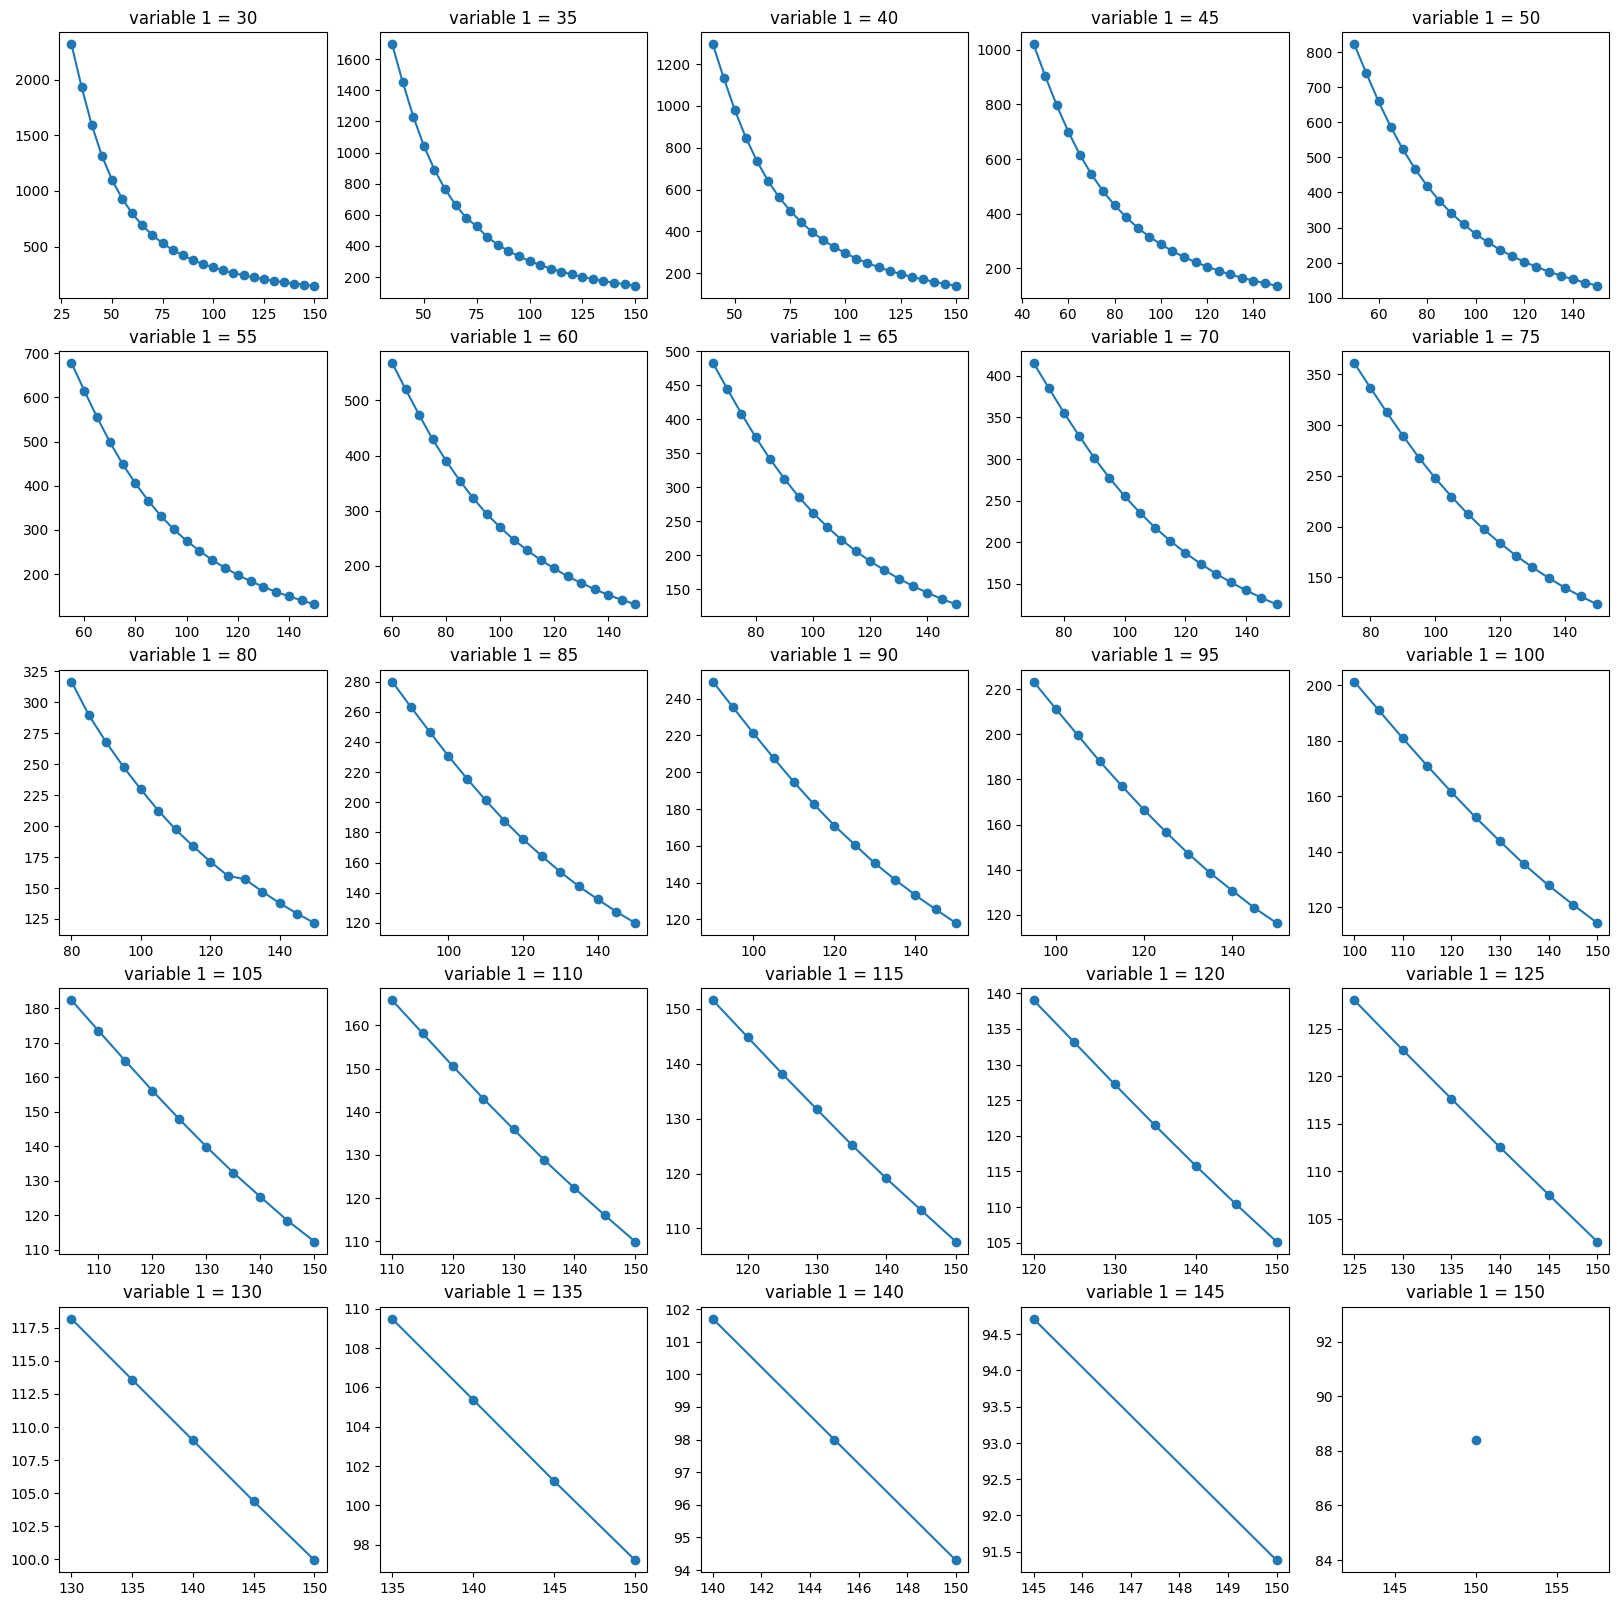

In [7]:
fig,ax = plt.subplots(5,5, figsize = (20,20))

for i in range(5):
    for j in range(5):
        temp = df[df['variable 1'] == var1[5*i+j]]
        ax[i,j].plot(temp['variable 2'], temp['Output'], marker = 'o')
        ax[i,j].set_title('variable 1 = '+str(var1[5*i+j]))

plt.show()

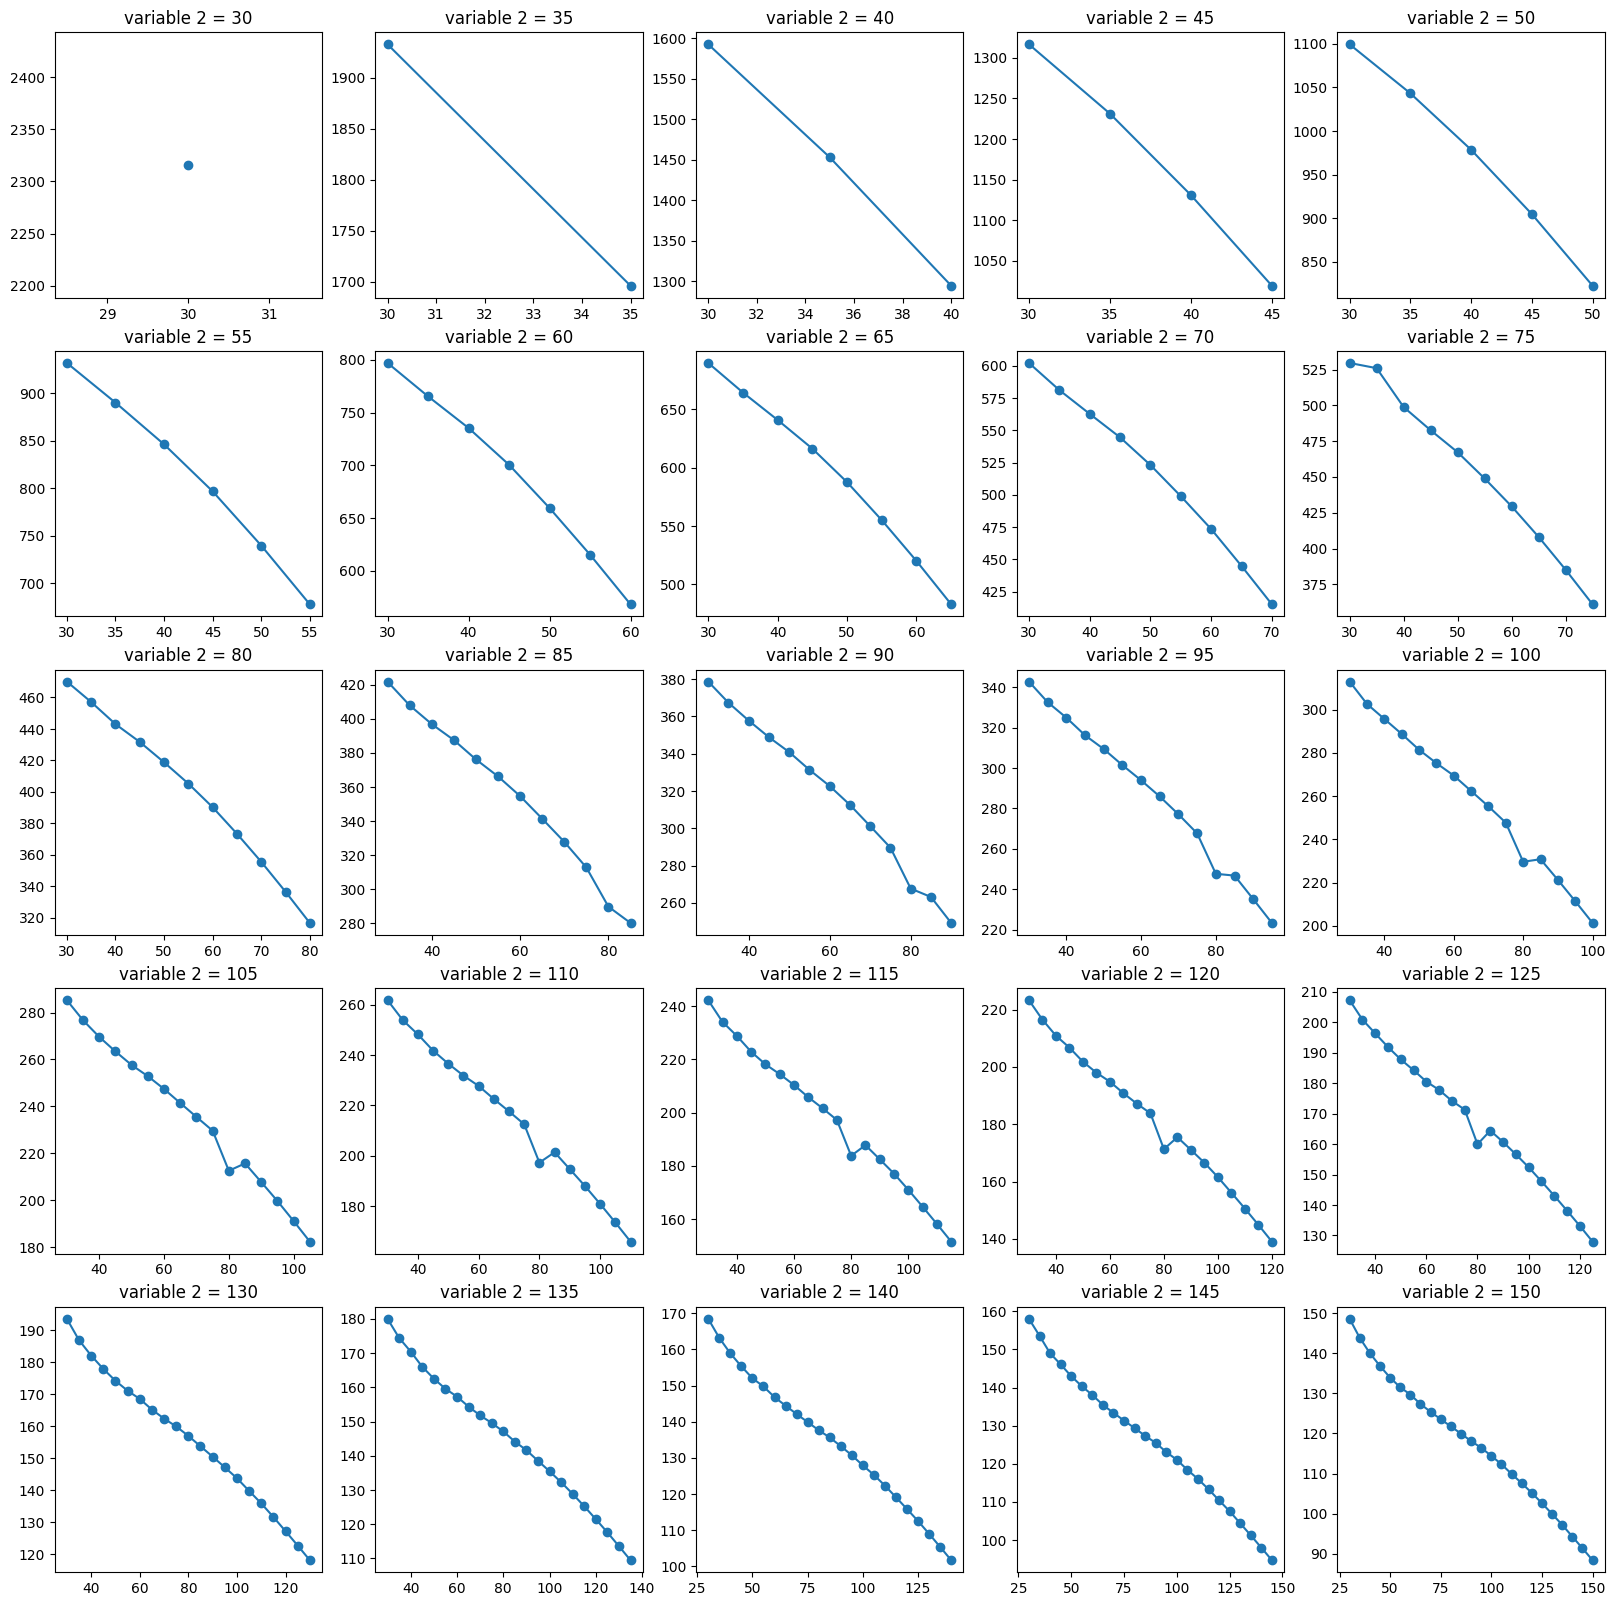

In [8]:
var2 = df['variable 2'].unique()
fig,ax = plt.subplots(5,5, figsize = (20,20))

for i in range(5):
    for j in range(5):
        temp = df[df['variable 2'] == var2[5*i+j]]
        ax[i,j].plot(temp['variable 1'], temp['Output'], marker = 'o')
        ax[i,j].set_title('variable 2 = '+str(var2[5*i+j]))

plt.show()

3D plot of Data

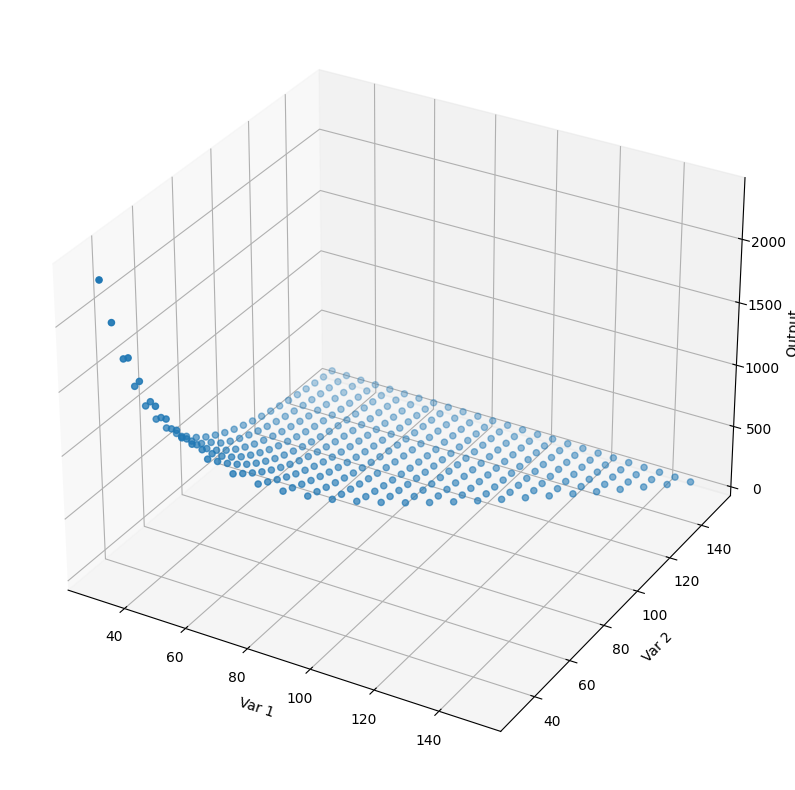

In [9]:
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(projection = '3d')
ax.scatter(df['variable 1'], df['variable 2'], df['Output'], marker = 'o')
ax.set_xlabel('Var 1')
ax.set_ylabel('Var 2')
ax.set_zlabel('Output')
plt.show()

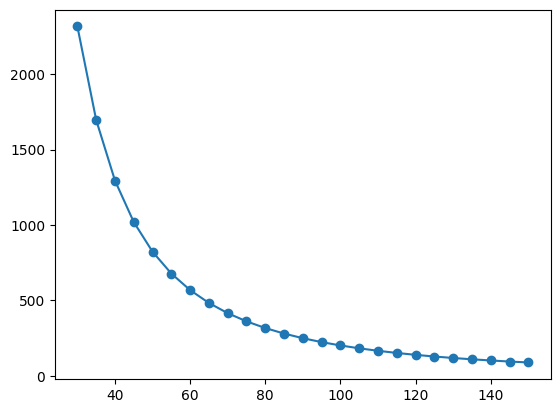

In [10]:
diag = df[df['variable 1'] == df['variable 2']]
plt.plot(diag['variable 1'], diag['Output'], marker = 'o')

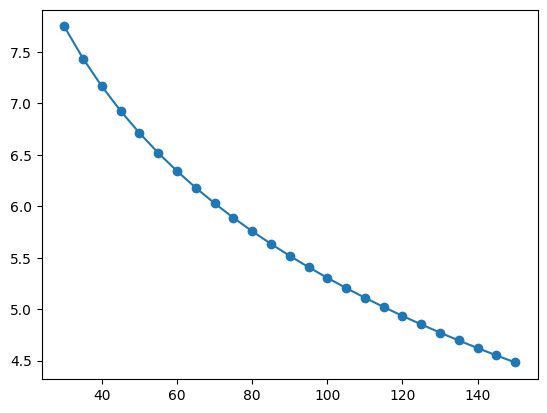

In [11]:
plt.plot(diag['variable 1'], np.log(diag['Output']), marker = 'o')

res.x:  84.90895790286837


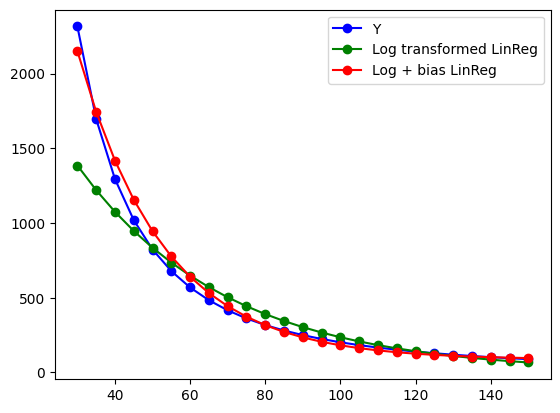

In [12]:
X = diag['variable 1']
Y = diag['Output']

b_upper = np.min(Y) - 1e-9
res = minimize_scalar(Jlogbiaslinmodel(X,Y), bounds = (-1e6, b_upper), method = 'bounded')
print('res.x: ',res.x)

m1,b1 = np.polyfit(X,np.log(Y),1)
Ypredlog = np.exp(m1*X+b1)

m2,b2 = np.polyfit(X,np.log(Y-res.x),1)
Ypredbias = np.exp(m2*X+b2) + res.x

plt.plot(X,Y,c = 'b', label = 'Y', marker = 'o')
plt.plot(X,Ypredlog,c = 'g', label = 'Log transformed LinReg', marker = 'o')
plt.plot(X,Ypredbias,c = 'r', label = 'Log + bias LinReg', marker = 'o')
plt.legend()

In [13]:
print('mse of log : ',mean_squared_error(Ypredlog,Y))
print('mse of log+bias : ',mean_squared_error(Ypredbias,Y))

mse of log :  47830.31065627976
mse of log+bias :  3951.5942797822627
